#**Artificial Intelligence**
## *Assignment 4: Descision Tree*
### Team:
#### Adrián Noriega Solís ID: 2111735
#### Aldo Reynold Alvarado Pérez ID: 2107251
#### Julieta Anahí Martínez Rangel ID: 2106210
#### Jorge Augusto Becerra Cifuentes ID: 2177839
#### Karla Ximena Rendón Calderón ID: 2044499

---
Class day & hour:
Tuesday at N4


Step 1: Import Libraries

In [ ]:
import matplotlib.pyplot as plt
import kagglehub
import pandas as pd
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn import tree

Step 2: Load Data

In [ ]:
# Importamos los datos descargados del Keggle
breast_cancer = pd.read_csv('data.csv')

In [ ]:
#Dividimos en los ejes X y Y; en el eje Y tomamos el diagnostico, y
#en el eje X quitamos la columna de diagnostico obvio, la id y la columna que está vacía.

X = breast_cancer.drop(columns=['diagnosis', 'Unnamed: 32', 'id'])
Y = breast_cancer['diagnosis']

In [ ]:
#Vemos las primeras 10 filas de las columnas y columnas de datos
print(X.head(10))


   radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   
5        12.45         15.70           82.57      477.1          0.12780   
6        18.25         19.98          119.60     1040.0          0.09463   
7        13.71         20.83           90.20      577.9          0.11890   
8        13.00         21.82           87.50      519.8          0.12730   
9        12.46         24.04           83.97      475.9          0.11860   

   compactness_mean  concavity_mean  concave points_mean  symmetry_mean  \
0           0.27760         0.30010              0.14710         0.2419   
1           0

In [ ]:
#Vemos los primeros 10 diagnosticos
print(Y.head(10))

0    M
1    M
2    M
3    M
4    M
5    M
6    M
7    M
8    M
9    M
Name: diagnosis, dtype: object


Step 3: Preprosessign

In [ ]:
#Verificamos q no hay valores nulos (aparte de la Unnamed 32)
print(breast_cancer.isnull().sum())

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [ ]:
#Seccionamos los ejes en muestras de entrenamiento y de testeo de manera aleatoria,
#usando 0.2 o 20% de muestra para el testeo
#  X_train,    X_test,      y_train,      y_test
train_data, test_data, train_labels, test_labels = train_test_split(X, Y, test_size=0.2, random_state=42)

Step 4: Select and train the model

In [ ]:
# Llamamos al tipo de modelo (Arbol de desición)
DTC = DecisionTreeClassifier()

In [ ]:
# Entrenamos al modelo
DTC.fit(train_data, train_labels)

DecisionTreeClassifier()

In [ ]:
# Exactitud del modelo en el entrenamiento. (1 es 100%)
train_accuracy = DTC.score(train_data, train_labels)
print("Train Accuracy:", train_accuracy)

Train Accuracy: 1.0


Step 5: Test the model

In [ ]:
#Aplicamos el modelo a predecir con los datos del test (testear)
predict = DTC.predict(test_data)

In [ ]:
#El primer numero es la predicción (arreglo NumPy)
#El segundo es el valor real (usamos .iloc para acceder por posición física)
# B = Benigno ; M = Maligno
print(predict[0])
print(test_labels.iloc[0])

B
B


In [ ]:
#Segunda predicción
print(predict[24])
print(test_labels.iloc[24])

B
B


In [ ]:
#Tercera predicción
print(predict[7])
print(test_labels.iloc[7])

M
M


In [ ]:
#Calculamos la certeza del modelo con los valores de testeo y las predicciónes
#La presición es todo lo que el modelo etiquetó correctamente o que tan seguido tiene razón
#El recall es, de todos los que marcó dentro de esa categoría, realmente pertenecen o cuantos hizo bien?
#El f1-score junta los dos anteriores en una media, se usa para comparar varios modelos
#El support es cuantas muestras reales habia, en este caso 71 benignas y 43 malignas
#La accuracy es la certeza lol osea 92.10%
#El macro avg promedio simple de las dos clases, sin considerar cuántas muestras tiene cada una.
#Y el weighted es el promedio pero ponderado por el support, osea como hay mas benignos, valen más

accuracy = accuracy_score(test_labels, predict)
print("Accuracy:", accuracy)
print("Classification Report:\n", classification_report(test_labels, predict))

Accuracy: 0.9210526315789473
Classification Report:
               precision    recall  f1-score   support

           B       0.94      0.93      0.94        71
           M       0.89      0.91      0.90        43

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



Decision Tree Visualization

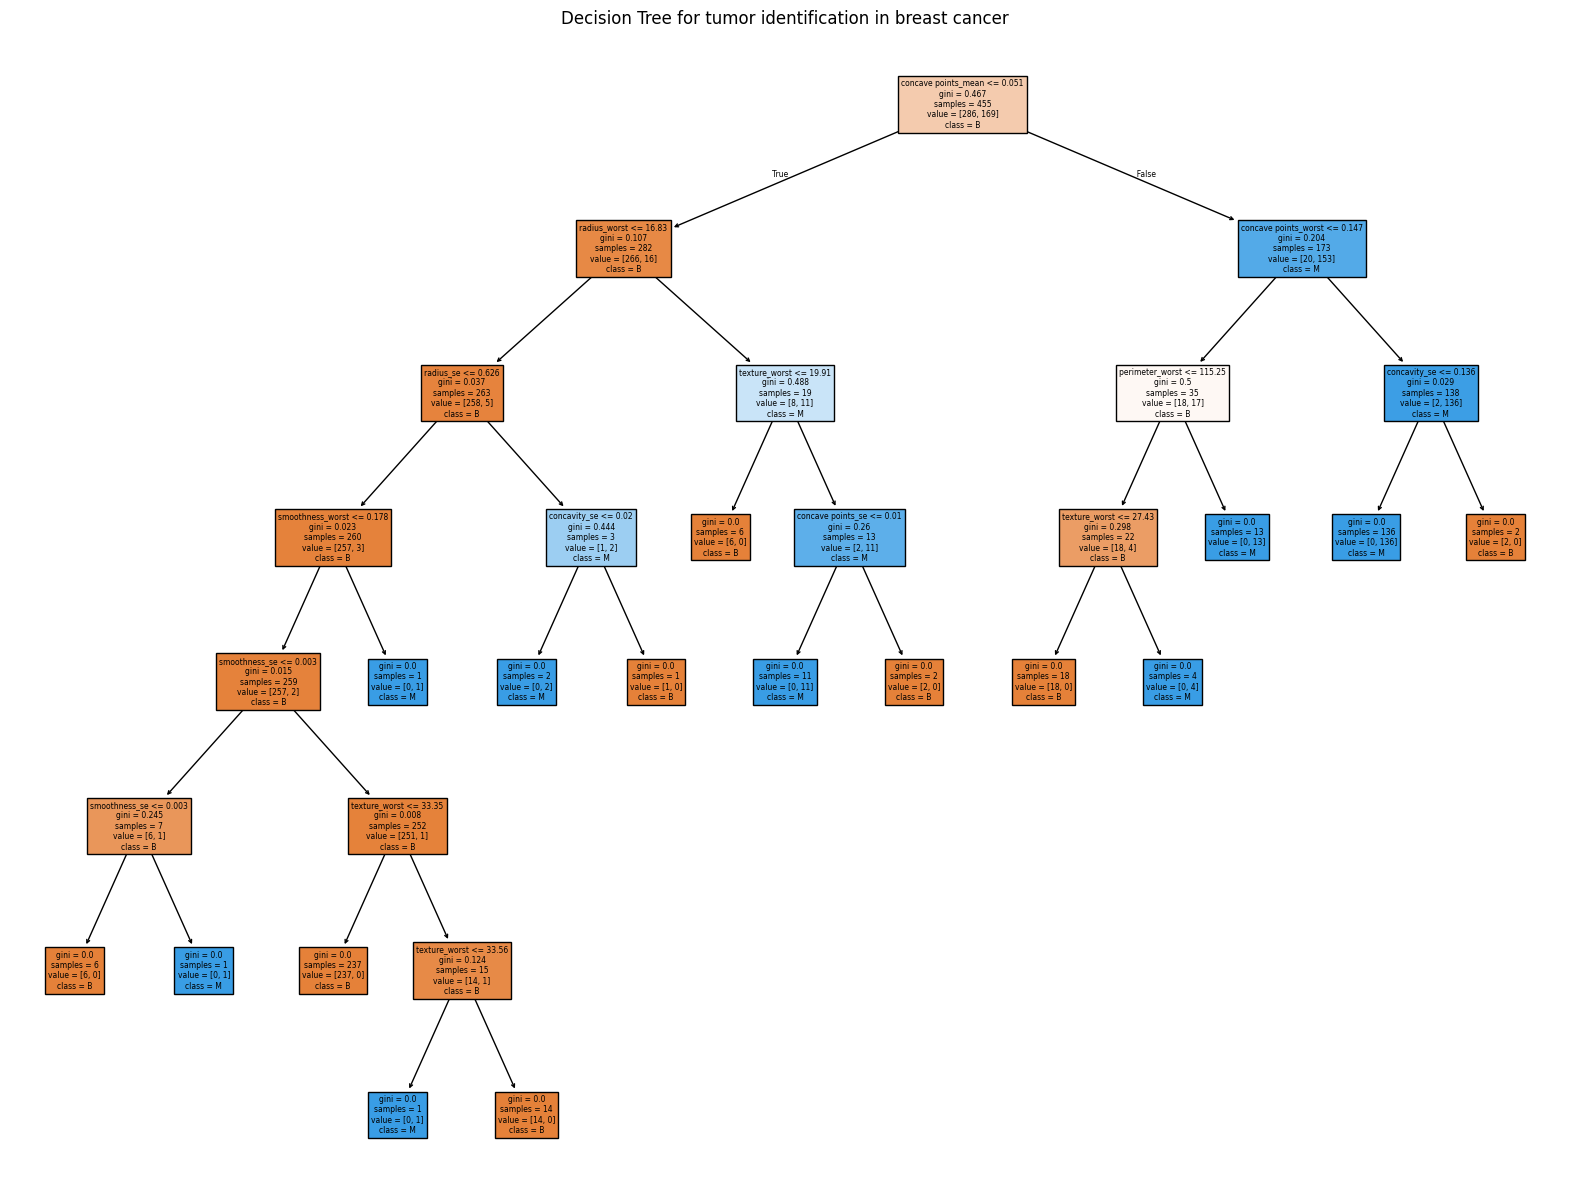

In [ ]:
#Damos las dimensiones de la figura, luego pedimos que de nuestro modelo tome las features de
#todos los datos, las clases y por ultimo el filled = true significa que se pone del color que va
#predominando la clase, el titulo es eso y el dpi es la resolución
plt.figure(figsize=(20, 15))
tree.plot_tree(DTC, feature_names=X.columns, class_names=['B', 'M'], filled=True)
plt.title("Decision Tree for tumor identification in breast cancer")
plt.savefig("decision_tree.png", dpi=300)
plt.show()